# PathSnap: Dataset Exploration (Phase 2)
Partitions used: **train (80 trips)** and **student_test (10 trips)**. Evaluator trips are never loaded.
All numbers come from `results/eda/trip_stats.csv`, produced by `pathsnap.eda` over the raw files.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from pathsnap.config import RESULTS, STUDENT_TEST_DIR, TRAIN_DIR
from pathsnap.geo import haversine_m, make_projector
from pathsnap.io import load_trip

sns.set_theme(style="whitegrid")
df = pd.read_csv(RESULTS / "eda" / "trip_stats.csv", dtype={"trip_id": str})
df["dir"] = df.partition.map({"train": TRAIN_DIR, "student_test": STUDENT_TEST_DIR})
print(df.shape)

(90, 34)


## 1. Dataset inventory

In [2]:
inv = df.groupby("partition").agg(
    trips=("trip_id", "count"), gps_points=("n_gps", "sum"), road_nodes=("n_nodes", "sum"),
    road_arcs=("n_arcs", "sum"), route_entries=("route_len", "sum"),
    median_gps_per_trip=("n_gps", "median"), median_route_per_trip=("route_len", "median"))
inv

,trips,gps_points,road_nodes,road_arcs,route_entries,median_gps_per_trip,median_route_per_trip
partition,,,,,,,
student_test,10,19160,90689,185041,3477,1420.0,250.0
train,80,208417,1933485,3876904,31336,1529.0,280.0


In [3]:
# file availability and sizes (MB) for every trip
rows = []
for r in df.itertuples():
    d = Path(r.dir) / r.trip_id
    rows.append({"partition": r.partition, "trip_id": r.trip_id,
                 **{e: (d / f"{r.trip_id}.{e}").stat().st_size / 1e6 if (d / f"{r.trip_id}.{e}").exists() else np.nan
                    for e in ["track", "nodes", "arcs", "route"]}})
sizes = pd.DataFrame(rows)
print("missing files:", int(sizes[["track", "nodes", "arcs", "route"]].isna().sum().sum()))
sizes.groupby("partition")[["track", "nodes", "arcs", "route"]].sum().round(1).rename(columns=lambda c: c + " (MB)")

missing files: 0


,track (MB),nodes (MB),arcs (MB),route (MB)
partition,,,,
student_test,0.6,1.8,1.9,0.0
train,6.9,38.4,44.3,0.2


## 2. GPS quality: missing values, timestamps, gaps, speed

In [4]:
q = df.groupby("partition")[["gps_nan", "lonlat_invalid"]].sum()
q["non_monotonic_trips"] = df.groupby("partition").t_monotonic.apply(lambda x: int((~x).sum()))
q["dt_median_s"] = df.groupby("partition").dt_median.median()
q["intervals_gt_1s"] = df.groupby("partition").n_dt_gt1.sum()
q["intervals_gt_10s"] = df.groupby("partition").n_dt_gt10.sum()
q["max_gap_s"] = df.groupby("partition").dt_max.max()
q

,gps_nan,lonlat_invalid,non_monotonic_trips,dt_median_s,intervals_gt_1s,intervals_gt_10s,max_gap_s
partition,,,,,,,
student_test,0,0,0,1.0,264,27,210.0
train,0,0,0,1.0,7286,590,153064.0


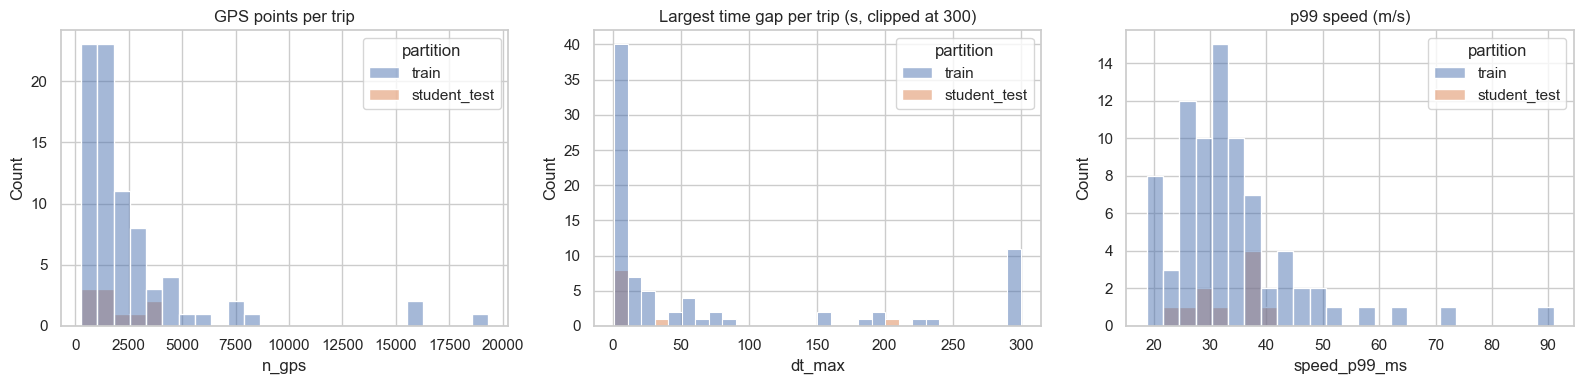

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(df, x="n_gps", hue="partition", bins=25, ax=ax[0]); ax[0].set_title("GPS points per trip")
sns.histplot(df, x=df.dt_max.clip(upper=300), hue="partition", bins=30, ax=ax[1])
ax[1].set_title("Largest time gap per trip (s, clipped at 300)")
sns.histplot(df, x="speed_p99_ms", hue="partition", bins=25, ax=ax[2]); ax[2].set_title("p99 speed (m/s)")
plt.tight_layout()

In [6]:
df.sort_values("dt_max", ascending=False)[["partition", "trip_id", "n_gps", "dt_max", "n_dt_gt10", "speed_max_ms"]].head(8)

,partition,trip_id,n_gps,dt_max,n_dt_gt10,speed_max_ms
72,train,00000090,536,153064.0,6,33.773038
61,train,00000078,2909,52810.0,25,50.831640
55,train,00000069,2067,2658.0,2,41.839309
16,train,00000021,15783,2161.0,2,45.949672
8,train,00000011,2828,909.0,1,50.323291
34,train,00000042,7739,670.0,37,58.394714
64,train,00000081,3224,536.0,86,40.358455
18,train,00000024,801,458.0,2,65.738946


## 3. Geographical extent

,extent_km,track_len_m,duration_s
count,90.0,90.0,90.0
mean,19.2,36393.1,5274.2
std,20.0,33391.6,17240.0
min,1.4,5546.8,265.0
25%,5.5,12765.3,1133.8
50%,9.5,24065.7,1710.0
75%,28.4,48762.7,3618.8
max,78.5,169253.8,154030.0


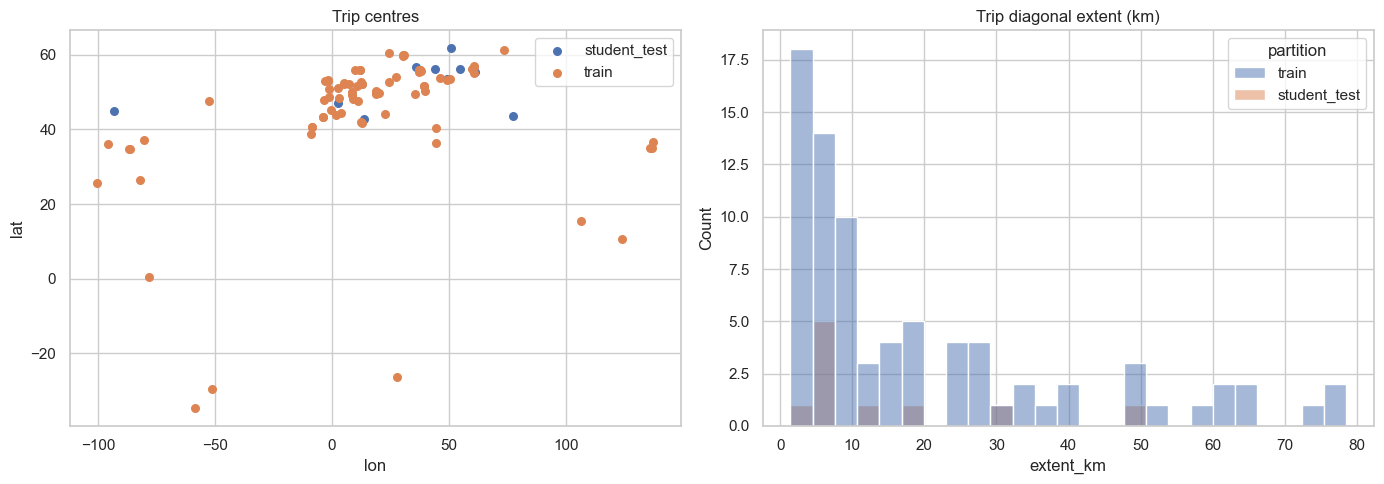

In [7]:
df["extent_km"] = [
    haversine_m(r.lon_min, r.lat_min, r.lon_max, r.lat_max) / 1000 for r in df.itertuples()]
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
for p, g in df.groupby("partition"):
    ax[0].scatter((g.lon_min + g.lon_max) / 2, (g.lat_min + g.lat_max) / 2, label=p, s=30)
ax[0].set_xlabel("lon"); ax[0].set_ylabel("lat"); ax[0].set_title("Trip centres"); ax[0].legend()
sns.histplot(df, x="extent_km", hue="partition", bins=25, ax=ax[1]); ax[1].set_title("Trip diagonal extent (km)")
plt.tight_layout()
df[["extent_km", "track_len_m", "duration_s"]].describe().round(1)

## 4. Road network: size and connectivity

In [8]:
net = df.groupby("partition")[["self_loops", "dup_arcs", "isolated_nodes", "arc_ref_invalid"]].sum()
net["median_weak_components"] = df.groupby("partition").weak_components.median()
net["median_nodes"] = df.groupby("partition").n_nodes.median()
net["median_arcs"] = df.groupby("partition").n_arcs.median()
net

,self_loops,dup_arcs,isolated_nodes,arc_ref_invalid,median_weak_components,median_nodes,median_arcs
partition,,,,,,,
student_test,2,128,0,0,11.0,6596.5,13145.0
train,22,1775,0,0,20.0,9608.0,19526.5


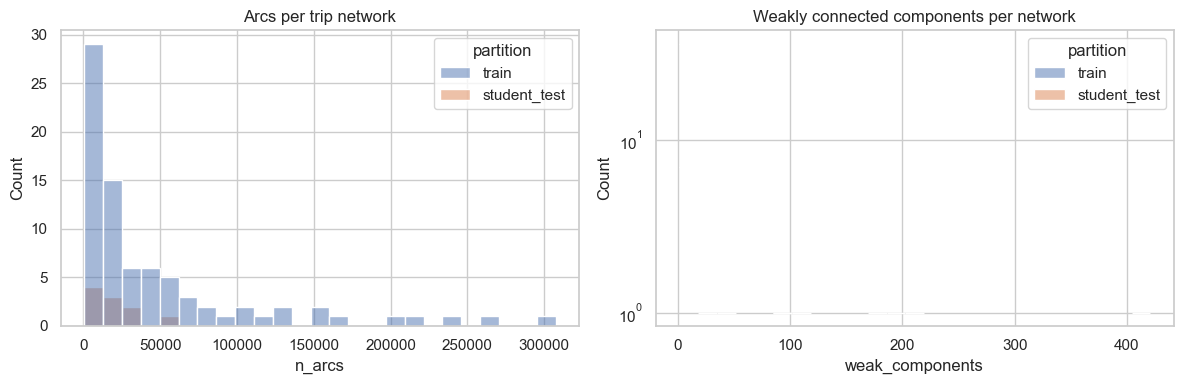

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df, x="n_arcs", hue="partition", bins=25, ax=ax[0]); ax[0].set_title("Arcs per trip network")
sns.histplot(df, x="weak_components", hue="partition", bins=25, ax=ax[1], log_scale=(False, True))
ax[1].set_title("Weakly connected components per network")
plt.tight_layout()

## 5. Reference route: structure and validity

In [10]:
rt = df.groupby("partition").agg(
    invalid_ids=("route_invalid_ids", "sum"), trips_not_fully_connected=("route_connected_frac", lambda x: int((x < 1).sum())),
    min_connected_frac=("route_connected_frac", "min"), repeated_arc_entries=("route_repeat_arcs", "sum"))
rt

,invalid_ids,trips_not_fully_connected,min_connected_frac,repeated_arc_entries
partition,,,,
student_test,0,1,0.997319,255
train,0,10,0.981308,67


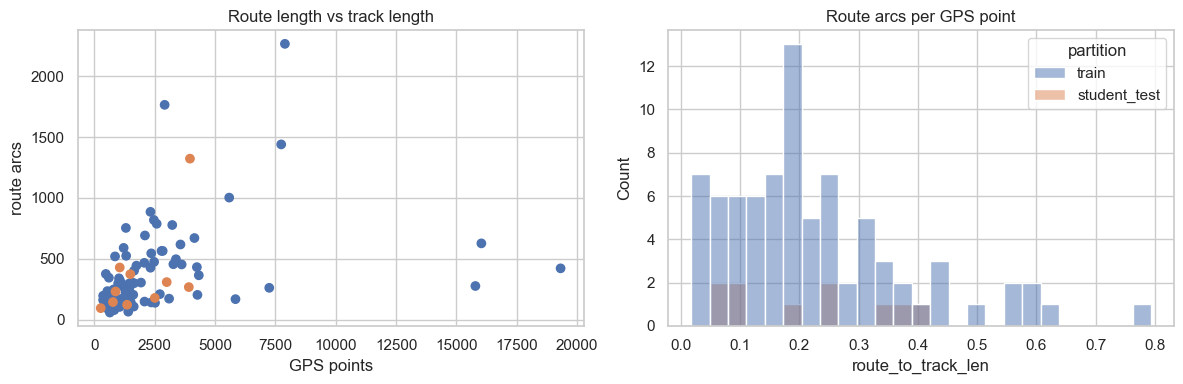

In [11]:
df["route_to_track_len"] = df.route_len / df.n_gps
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].scatter(df.n_gps, df.route_len, c=(df.partition == "train").map({True: "C0", False: "C1"}))
ax[0].set_xlabel("GPS points"); ax[0].set_ylabel("route arcs"); ax[0].set_title("Route length vs track length")
sns.histplot(df, x="route_to_track_len", hue="partition", bins=25, ax=ax[1]); ax[1].set_title("Route arcs per GPS point")
plt.tight_layout()

## 6. How far is GPS from the reference route? (unordered nearest-arc check)

,partition,trip_id,n_gps,gps_within_30m,gps_route_d_p95,gps_route_d_max
44,train,00000054,19313,0.114586,209.605483,240.757202
26,train,00000033,5844,0.291068,142.022283,160.412835
1,train,00000002,7243,0.859865,242.220711,569.485149
35,train,00000043,2322,0.874677,70.033854,192.781954
64,train,00000081,3224,0.933313,38.151151,111.514946
67,train,00000084,16031,0.933878,36.302941,104.571358


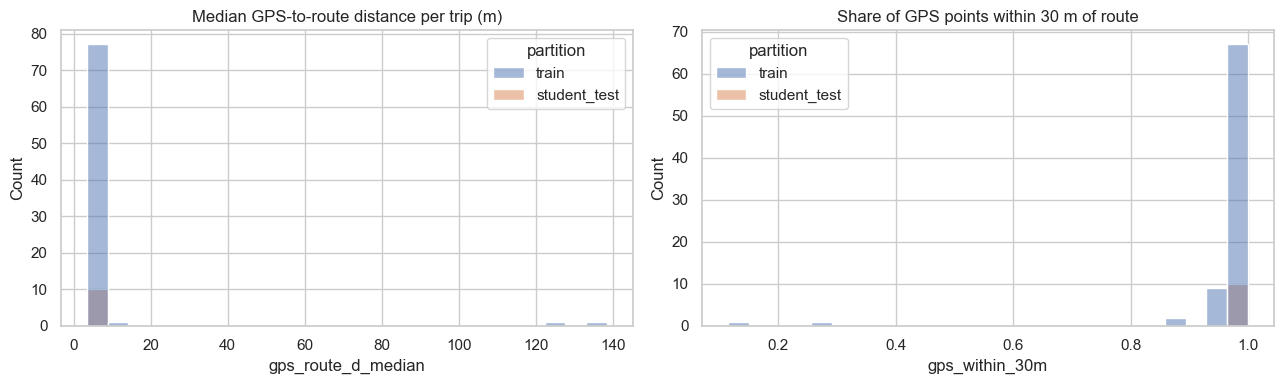

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(df, x="gps_route_d_median", hue="partition", bins=25, ax=ax[0]); ax[0].set_title("Median GPS-to-route distance per trip (m)")
sns.histplot(df, x="gps_within_30m", hue="partition", bins=25, ax=ax[1]); ax[1].set_title("Share of GPS points within 30 m of route")
plt.tight_layout()
df.sort_values("gps_within_30m")[["partition", "trip_id", "n_gps", "gps_within_30m", "gps_route_d_p95", "gps_route_d_max"]].head(6)

## 7. Trajectories against the reference route (matplotlib)

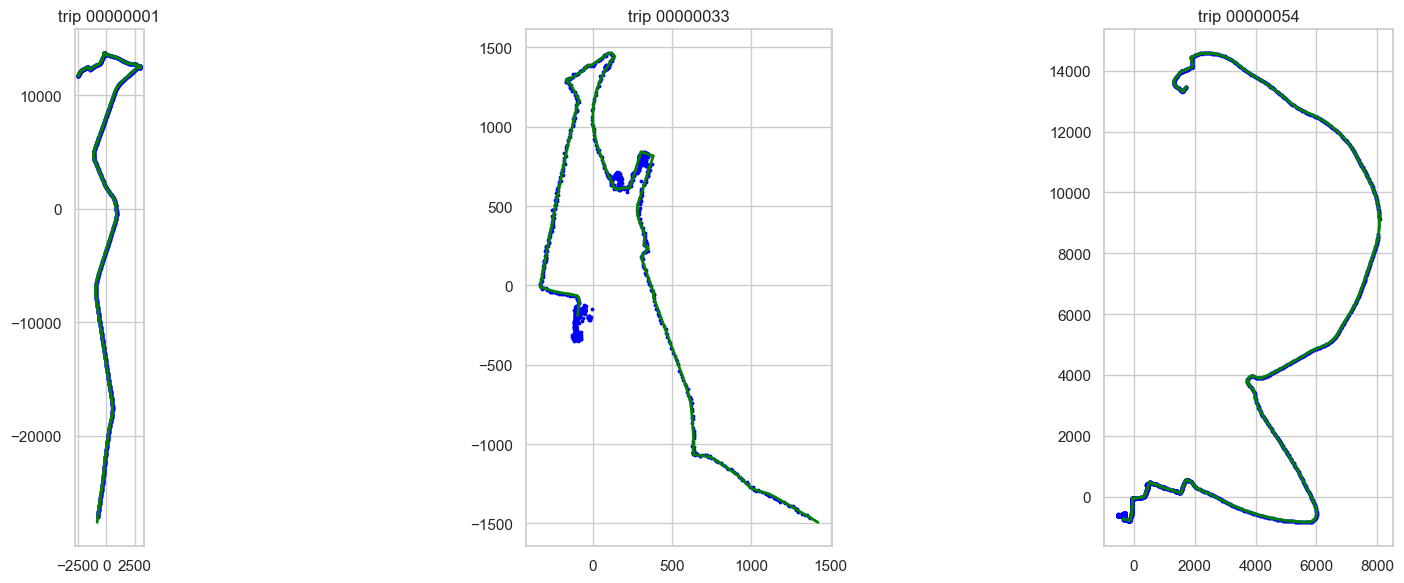

In [13]:
def plot_trip(ax, part_dir, tid):
    t = load_trip(part_dir / tid)
    tr, nodes, arcs, r = t["track"], t["nodes"], t["arcs"], t["route"].arc_id.values
    proj = make_projector(tr.lon.mean(), tr.lat.mean())
    nx, ny = proj(nodes.lon.values, nodes.lat.values)
    px, py = proj(tr.lon.values, tr.lat.values)
    a, b = arcs.from_node.values[r], arcs.to_node.values[r]
    for i in range(len(r)):
        ax.plot([nx[a[i]], nx[b[i]]], [ny[a[i]], ny[b[i]]], color="green", lw=2)
    ax.scatter(px, py, s=3, color="blue")
    ax.set_title(f"trip {tid}"); ax.set_aspect("equal")

fig, ax = plt.subplots(1, 3, figsize=(18, 6))
plot_trip(ax[0], TRAIN_DIR, "00000001")
plot_trip(ax[1], TRAIN_DIR, "00000033")   # lowest GPS-to-route agreement
plot_trip(ax[2], TRAIN_DIR, "00000054")   # worst agreement (11% within 30 m)
plt.tight_layout()

## 8. Interactive Folium map (train trip 00000001)

In [14]:
from pathsnap.viz import trip_map
m_path = trip_map(load_trip(TRAIN_DIR / "00000001"))
import html
from IPython.display import HTML
HTML('<iframe srcdoc="' + html.escape(m_path.read_text(encoding="utf8")) + '" width="100%" height="550"></iframe>')

C:\Users\Adil Ahmed\AppData\Roaming\Python\Python310\site-packages\IPython\core\display.py:475: UserWarning: Consider using IPython.display.IFrame instead
  warnings.warn("Consider using IPython.display.IFrame instead")


## 9. Findings and decisions
_filled in after inspecting the outputs above_